In [ ]:
import numpy as np
from scipy.special import sph_harm, genlaguerre, factorial
from mpl_toolkits.mplot3d import Axes3D

import matplotlib.pyplot as plt
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'          
plt.rcParams['font.serif'] = ['Computer Modern Serif']  

def orbital(n, l, m, probabilitydensity=1e-5, a=1):
    # Grid setup
    border = 32
    accuracy = 200
    raster = np.linspace(-border, border, accuracy)
    x, y, z = np.meshgrid(raster, raster, raster, indexing='ij')
    r = np.sqrt(x**2 + y**2 + z**2)
    theta = np.arccos(np.divide(z, r, out=np.zeros_like(z), where=r!=0))
    phi = np.arctan2(y, x)
    
    # Radial part
    def R(n, l, r):
        rho = 2 * r / (a * n)
        norm = np.sqrt((2/(a*n))**3 * factorial(n-l-1)/(2*n*factorial(n+l)))
        laguerre = genlaguerre(n-l-1, 2*l+1)(rho)
        return norm * np.exp(-rho/2) * rho**l * laguerre

    # Angular part (real spherical harmonics)
    def Y(l, m, theta, phi):
        if m < 0:
            return np.sqrt(2) * (-1)**m * sph_harm(abs(m), l, phi, theta).imag
        elif m == 0:
            return sph_harm(0, l, phi, theta).real
        else:
            return np.sqrt(2) * (-1)**m * sph_harm(m, l, phi, theta).real

    psi = R(n, l, r) * Y(l, m, theta, phi)
    prob = np.abs(psi)**2
    mask = prob > probabilitydensity
    return x[mask], y[mask], z[mask], np.sign(psi[mask])

    # # Isosurface plotting
    # fig = plt.figure(figsize=(8,8))
    # ax = fig.add_subplot(111, projection='3d')
    # # Mask for isosurface
    # mask = prob > probabilitydensity
    # ax.scatter(x[mask], y[mask], z[mask], c=np.sign(psi[mask]), cmap='coolwarm', s=1)
    # #ax.set_title(f'n={n}, l={l}, m={m}', fontsize=20)
    # ax.set_box_aspect(None, zoom=0.85)
    # ax.set_xlabel('$x_1$', fontsize=25, labelpad=10)
    # ax.set_ylabel('$x_2$', fontsize=25, labelpad=10)
    # ax.set_zlabel('$x_3$', fontsize=25, labelpad=10)
    # ax.tick_params(axis="both", labelsize=20)
    # plt.show()
    # if (n == 2 and l == 0 and m == 0) or (n == 2 and l == 1 and m == 1) or (n == 3 and l == 2 and m == 2) or (n == 3 and l == 2 and m == 0):
    #     fig.savefig(f'./figures/hydrogen_exact_n{n}_l{l}_m{m}.pdf', bbox_inches="tight", dpi=300)


# # Loop through quantum numbers and plot
# for n in range(1, 4):
#     for l in range(0, n):
#         for m in range(-l, l+1):
#             plot_orbital(n, l, m)
#             #if (n == 2 and l == 0 and m == 0) or (n == 2 and l == 1 and m == 1) or (n == 3 and l == 2 and m == 2) or (n == 3 and l == 2 and m == 0):
#                 #fig.savefig(f'./figures/hydrogen_exact_n{n}_l{l}_m{m}.pdf', bbox_inches="tight", dpi=300)


orbital1 = orbital(n=2, l=0, m=0)
orbital2 = orbital(n=2, l=1, m=1)
orbital3 = orbital(n=3, l=2, m=2)
orbital4 = orbital(n=3, l=2, m=0)

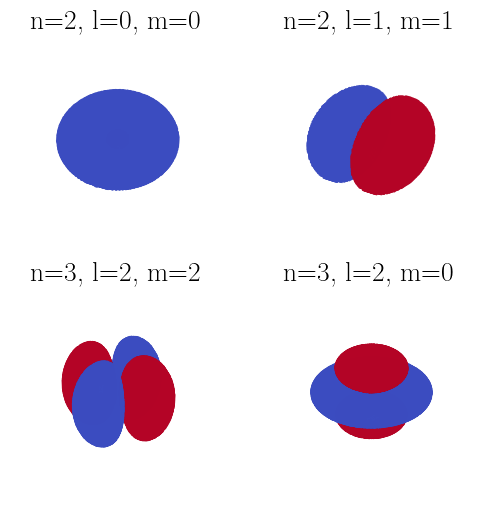

In [ ]:


fig, axes = plt.subplots(2,2,
                         subplot_kw={'projection':'3d'},
                         figsize=(6,6))
axes = axes.flatten()
axes[0].scatter(orbital1[0], orbital1[1], orbital1[2], c=orbital1[3], cmap='coolwarm', s=1)
axes[0].set_title('n=2, l=0, m=0', fontsize=20)

axes[1].scatter(orbital2[0], orbital2[1], orbital2[2], c=orbital2[3], cmap='coolwarm', s=1)
axes[1].set_title('n=2, l=1, m=1', fontsize=20)

axes[2].scatter(orbital3[0], orbital3[1], orbital3[2], c=orbital3[3], cmap='coolwarm', s=1)
axes[2].set_title('n=3, l=2, m=2', fontsize=20)

axes[3].scatter(orbital4[0], orbital4[1], orbital4[2], c=orbital4[3], cmap='coolwarm', s=1)
axes[3].set_title('n=3, l=2, m=0', fontsize=20)
for ax in axes:
    ax.set_axis_off()
#fig.savefig('./figures/hydrogen_exact.png', bbox_inches="tight", dpi=300)
plt.show()

/tmp/ipykernel_10531/1191073572.py:32: DeprecationWarning: `scipy.special.sph_harm` is deprecated as of SciPy 1.15.0 and will be removed in SciPy 1.17.0. Please use `scipy.special.sph_harm_y` instead.
  return sph_harm(0, l, phi, theta).real


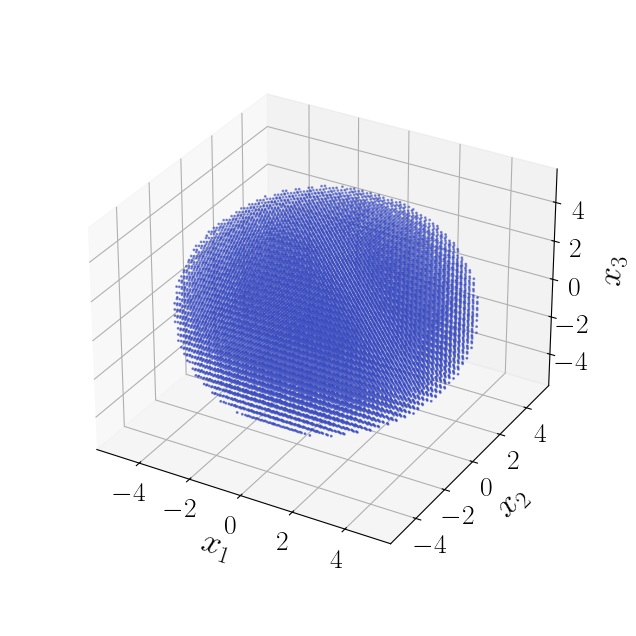

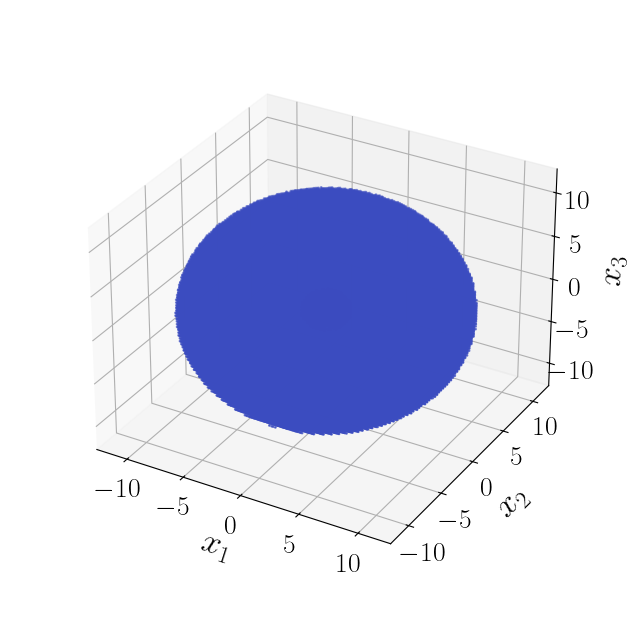

/tmp/ipykernel_10531/1191073572.py:30: DeprecationWarning: `scipy.special.sph_harm` is deprecated as of SciPy 1.15.0 and will be removed in SciPy 1.17.0. Please use `scipy.special.sph_harm_y` instead.
  return np.sqrt(2) * (-1)**m * sph_harm(abs(m), l, phi, theta).imag


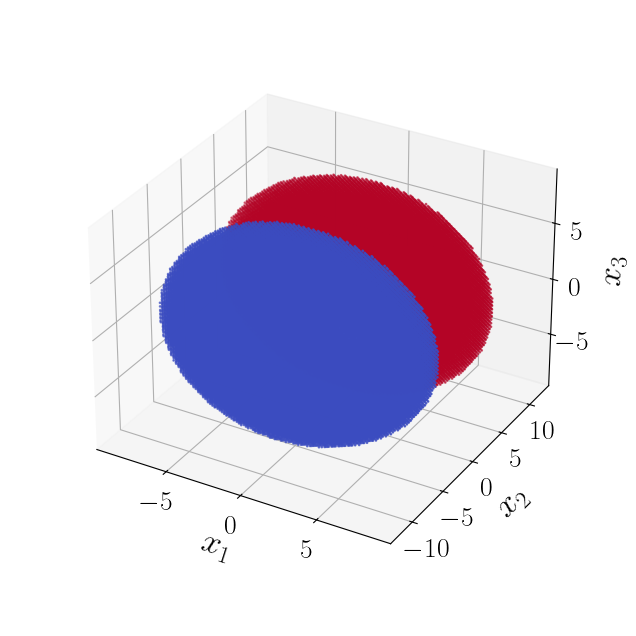

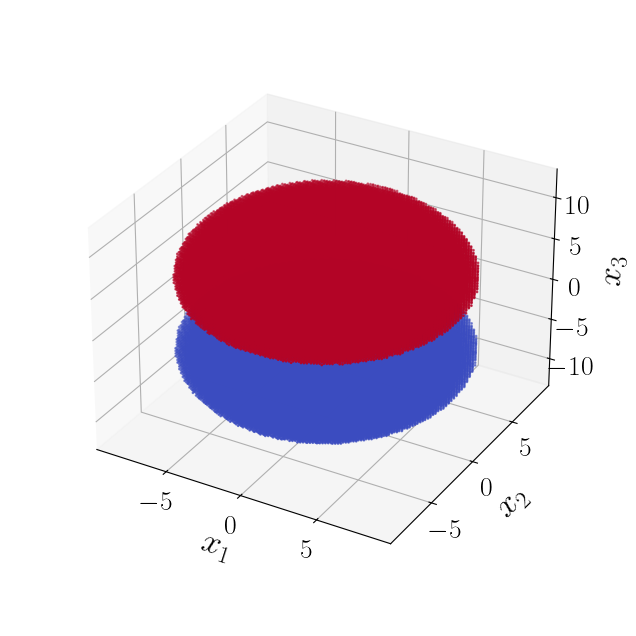

/tmp/ipykernel_10531/1191073572.py:34: DeprecationWarning: `scipy.special.sph_harm` is deprecated as of SciPy 1.15.0 and will be removed in SciPy 1.17.0. Please use `scipy.special.sph_harm_y` instead.
  return np.sqrt(2) * (-1)**m * sph_harm(m, l, phi, theta).real


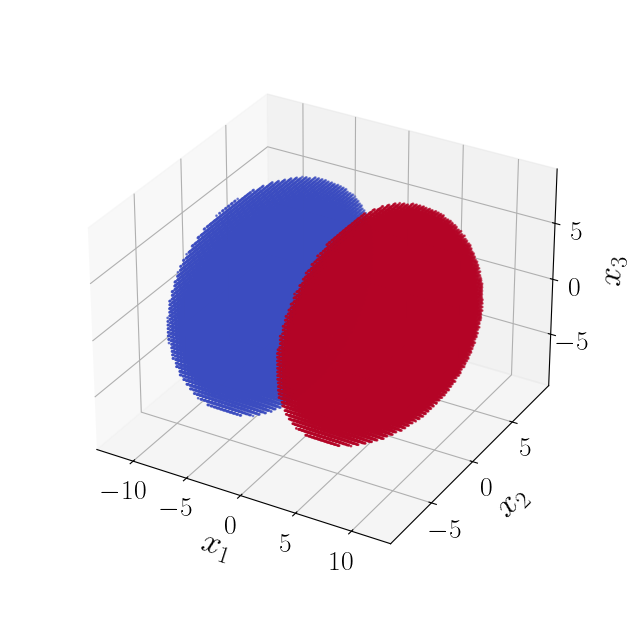

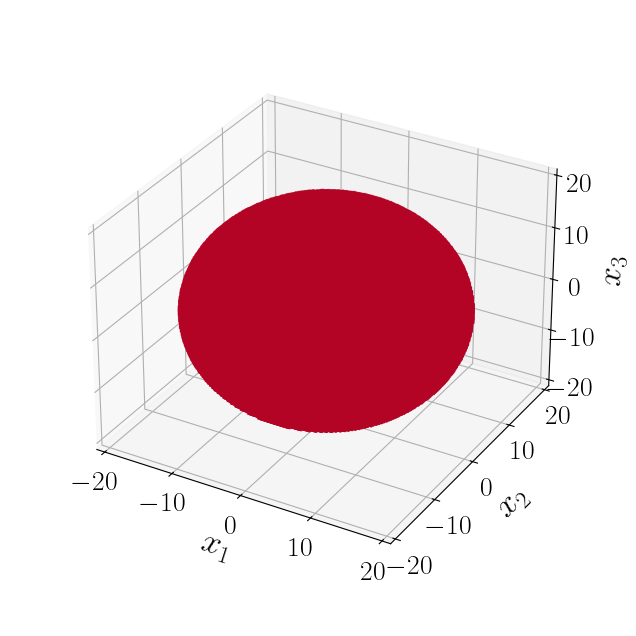

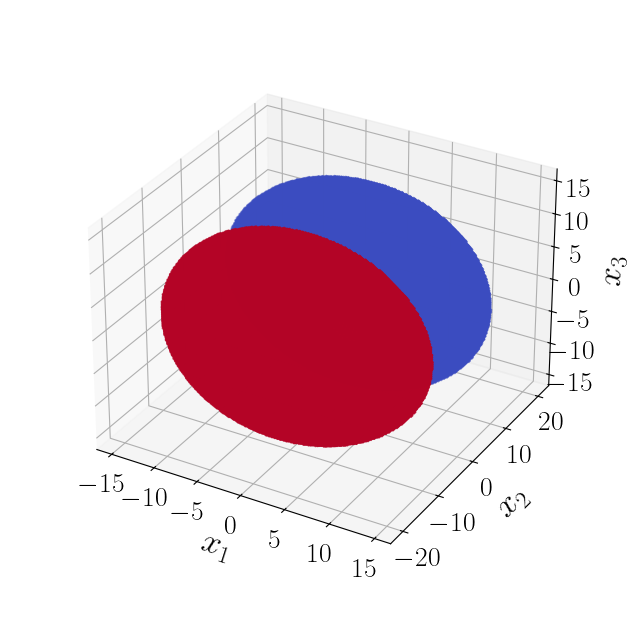

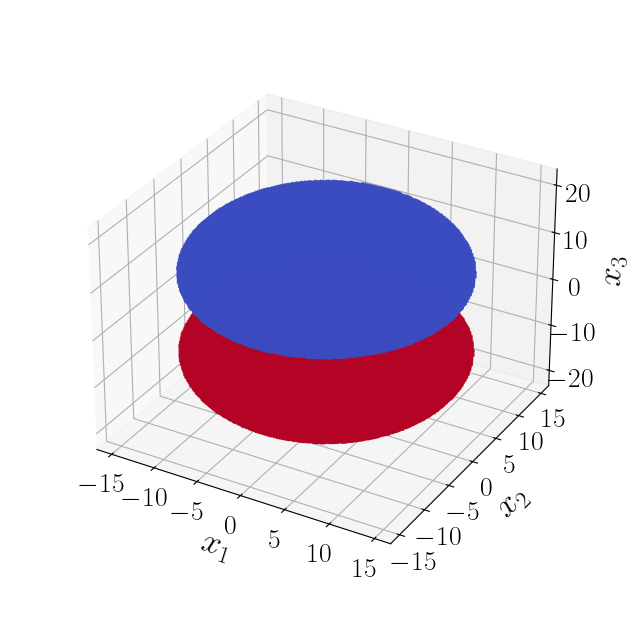

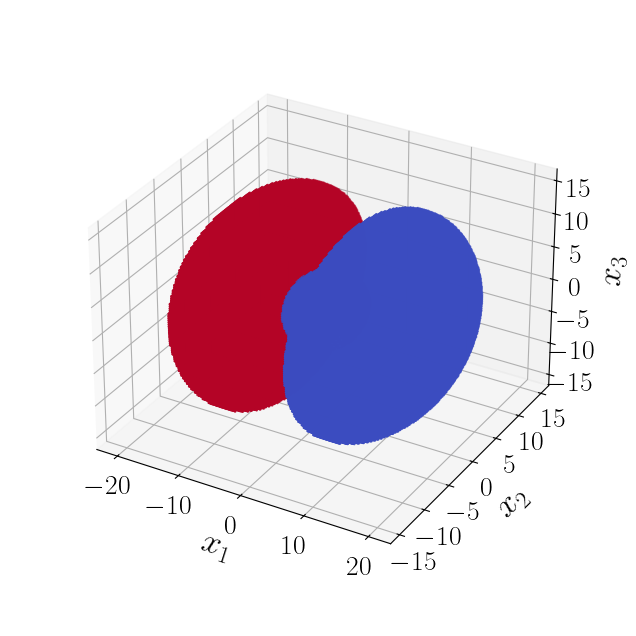

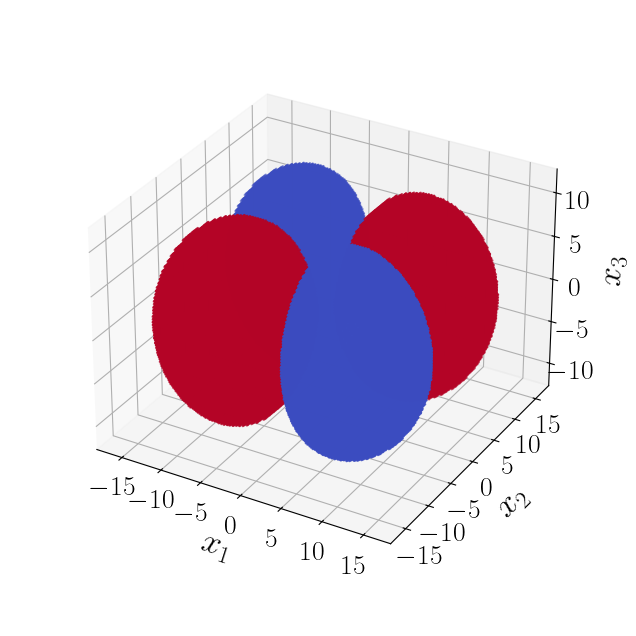

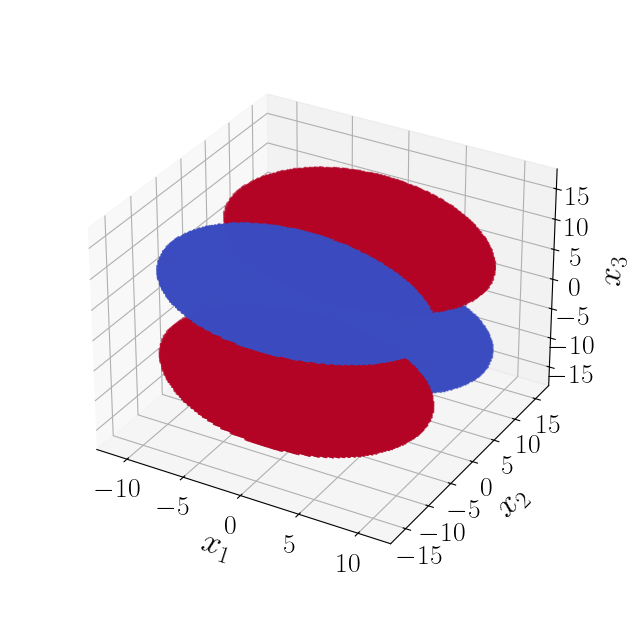

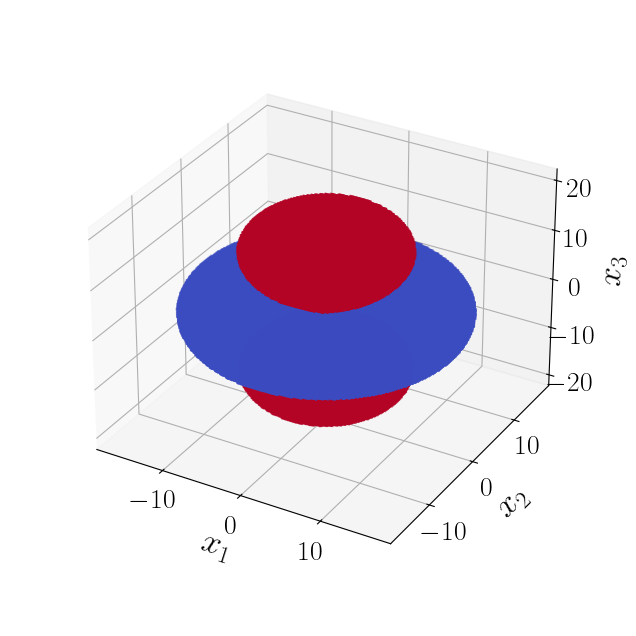

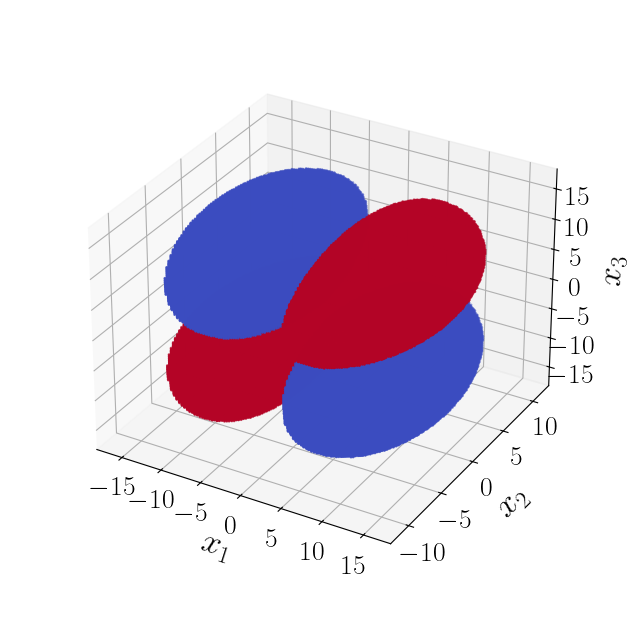

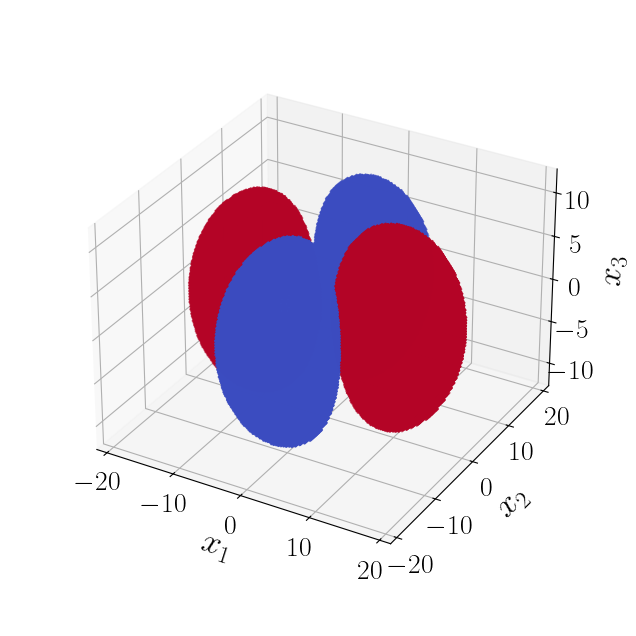